# Evolution du comportement d'achat

**Objectif**: Comprendre comment le comportement d'achat varie selon le profil du client (occasionnel, typique, fidèle) et identifier les produits qui génèrent de la récurrence.

**Questions à traiter**:

1. Comment évoluent les quantités d'achat selon le segment client ?
2. Quel est le taux de réachat global et par segment ?
3. Quels sont les produits les plus rachetés ?

**Impact business attendu**:
Identifier à quel moment les clients deviennent fidèles pour concentrer les actions de rétention sur les commandes critiques.

## Setup

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('..')

from src.data_loader import get_data
from src.features import enrich_dataframe

# Style global — palette sur mesure
sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

# Chargement
data = get_data(raw_dir="../data/raw/",processed_path="../data/processed/merged_orders.parquet")
data = enrich_dataframe(data)
print(f"Dataset: {data.shape[0]:,} lignes, {data.shape[1]:,} colonnes")
data.head(3)


Chargement depuis le cache .parquet
Dataset: 32,434,489 lignes, 21 colonnes


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,...,department_id,aisle,department,user_total_orders,customer_segment,cart_size,dept_per_order,aisles_per_order,day_name,hour_period
0,2,33120,1,1,202279,3,5,9,8.0,Organic Egg Whites,...,16,eggs,dairy eggs,8,typique,9,3,8,Vendredi,Matin
1,2,28985,2,1,202279,3,5,9,8.0,Michigan Organic Kale,...,4,fresh vegetables,produce,8,typique,9,3,8,Vendredi,Matin
2,2,9327,3,0,202279,3,5,9,8.0,Garlic Powder,...,13,spices seasonings,pantry,8,typique,9,3,8,Vendredi,Matin


## Vérification rapide de la segmentation

Avant d'analyser =, on vérifie que les 3 segments sont bien répartis et cohérents avec les quartiles observés dans le notebook 01.

### Distribution des utilisateurs par segment

In [15]:
users = data.groupby("user_id").agg(
    segment=("customer_segment", "first"),
    total_orders=("user_total_orders", "first")
).reset_index()

print("Répartition des utilisateurs par segment :")
print(users["segment"].value_counts().sort_index())
print(f"\nTotal : {len(users):,} utilisateurs")

Répartition des utilisateurs par segment :
segment
occasionnel    73591
typique        84808
fidèle         47810
Name: count, dtype: int64

Total : 206,209 utilisateurs


## 1- Comment évoluent les quantités d'achat selon le segment client ?

On cherche à savoir si les clients fidèles commandent plus d'articles par commandes que les occasionnels, et si la taille du panier évolue au fil des commandes.

L'objectif serait de mettre en place des cartes de fidélité afin de récompenser la fidélité de la clientèle, mais inciterait également à acheter plus.

In [16]:
# Statistiques descriptives de la taille du panier par segment
orders_level = data.groupby(["order_id", "customer_segment", "order_number"]).agg(
    cart_size =("product_id", "count")
).reset_index()

orders_level.groupby("customer_segment")["cart_size"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
customer_segment,,,,,,,,
occasionnel,314243.0,9.7,7.4,1.0,4.0,8.0,13.0,101.0
typique,1000376.0,10.0,7.5,1.0,5.0,8.0,14.0,121.0
fidèle,1900255.0,10.2,7.5,1.0,5.0,8.0,14.0,145.0


/tmp/ipykernel_8593/2841694528.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


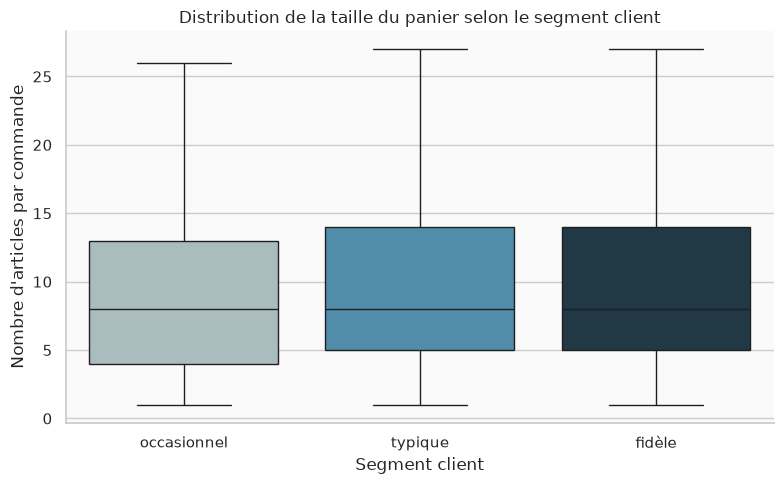

In [20]:
# Visualisation 1: Box plot, distribution de la taille du panier par segment
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=orders_level,
    x="customer_segment",
    y="cart_size",
    palette=PAL_SEGMENTS,
    showfliers=False,
    ax=ax
)

ax.set_xlabel("Segment client")
ax.set_ylabel("Nombre d'articles par commande")
ax.set_title("Distribution de la taille du panier selon le segment client")

plt.tight_layout()
plt.show()

### Interprétation

D'après les calculs, les trois segments présentent un comportement d'achat homogène en termees de taille de panier.

La **médiane** est identique, 8 articles, quel que soit le segment. L'écart entre occasionnels et fidèles n'est que de **+0.5 article en moyenne**, soit une différence de ~5 %, mais **négligeable en pratique**.

On peut déduire que la fidélité se traduit par une fréquence de commande plus élevée, et non par des paniers plus gros.
Un client fidèle ne remplit pas plus son panier, mais il revient simplement plus souvent.

### Implication business : 

un programme de fidélité classique (carte à points sur le montant) aurait un impact limité puisque la taille du panier est stable. Il serait plus pertinent de **récompenser la fréquence** plutôt que le volume par commande.

Ce graphique en barres rend visible ce que le boxplot masque : les trois barres sont quasi identiques, ce qui renforce visuellement le constat que la fidélité n'augmente pas la taille du panier.

## 2- Quel est le taux de réachat global et par segment client ?

La colonne reordered vaut 1 si le client a déjà commandé "ce produit avant", sinon 0. Un taux élevé signifi que les client rachètent les mêmes produits, signe d'habitudes et de fidélité produit.

In [ ]:
# Taux de réachat global
global_reorder = data["reordered"].mean()
print(f"Taux de réachat global: {global_reorder:.1%}")

# Par segment
reorder_by_segment = (
    data.groupby("customer_segment", observed=True)["reordered"]
    .mean()
    .reset_index()
    .rename(columns={"reordered": "taux_reachat"})
)
reorder_by_segment["taux_reachat_pct"] = (reorder_by_segment["taux_reachat"] * 100).round(1)
reorder_by_segment

Taux de réachat global: 59.0%


,customer_segment,taux_reachat,taux_reachat_pct
0,occasionnel,0.282336,28.2
1,typique,0.485731,48.6
2,fidèle,0.692028,69.2


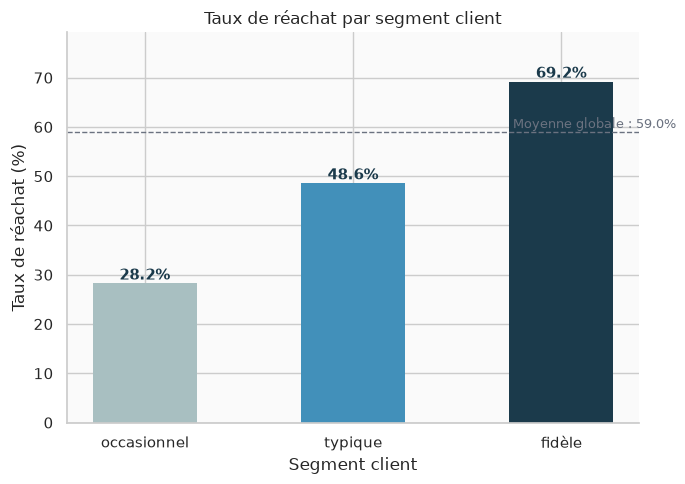

In [ ]:
# Visualisation : taux de réachat par segment
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    reorder_by_segment["customer_segment"].astype(str),
    reorder_by_segment["taux_reachat"] * 100,
    color=PAL_SEGMENTS,
    edgecolor="none",
    width=0.5
)

# Ligne de moyenne globale
ax.axhline(y=global_reorder * 100, color=COLORS["grey"], linestyle="--", linewidth=1)
ax.text(
    2.55, global_reorder * 100 + 0.8,
    f"Moyenne globale : {global_reorder:.1%}",
    color=COLORS["grey"], fontsize=9, ha="right"
)

# Annotations sur les barres
for bar, val in zip(bars, reorder_by_segment["taux_reachat_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
        f"{val}%", ha="center", fontsize=11, fontweight="bold", color=COLORS["fidèle"]
    )

ax.set_xlabel("Segment client")
ax.set_ylabel("Taux de réachat (%)")
ax.set_title("Taux de réachat par segment client")
ax.set_ylim(0, max(reorder_by_segment["taux_reachat"] * 100) + 10)

plt.tight_layout()
plt.show()

### Interprétation:

Le taux de réachat varie entre segment, avec une moyenne de 59% de taux de réachat.
Les clients occasionnels ont un taux de réachat de 28.2% (bien en dessous de la moyenne)
Les clients typiques ont un taux de réachat se rapprochant de la moyenne, soit 48,6%.
Et les client fidèles ont un taux de réachat supérieur à la moyenne, soit 69,2 %.

Nous avons constaté précédemment que la taille du panier était quasi identique entre segments (~8 articles). Le taux de réachat révèle une différence significative : un client fidèle rachète 7 produits sur 10* qu'il a déjà commandés, contre moins de 3 sur 10 chez un occasionnel.

Cela confirme le constat précédent: la fidélité se traduit par la récurrence, et non par le volume.

### Implication business

Nous pouvons emmettre 3 hypothèses concernant cette analyse:

- **Hypothèse 1: Produits ancres** : certains produits à fort taux de réachat "verrouillent" le client sur la plateforme (produits du quotidien indispensables).
- **Hypothèse 2: Confiance envers la plateforme** : le client revient par habitude ou satisfaction globale du service, indépendamment des produits spécifiques.
- **Hypothèse 3: Effet d'habitude de commande** : les clients fidèles utilisent la fonction "recommander" ou reconstituent un panier type par automatisme, ce qui gonfle mécaniquement le taux de réachat.
